# 01 · Funnel and cohort statistics (GA4, observational)
**Data:** GA4 obfuscated Google Merchandise Store sample, full 92 days (2020-11-01 to 2021-01-31), 4.3M events.
**Mapping:** `first_visit` stands in for sign-up, `purchase` for conversion, return visits for retention.
**Population:** new users (first_visit inside the sample) not flagged as bots. The funnel uses a 7-day window from the first visit, so only users with t0 + 7d ≤ the sample end are included.
**Status:** associations in an obfuscated sample. Definitions: `docs/metric_definitions.md`.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
FIG = ROOT / "reports" / "figures"

In [2]:
from src.analysis import funnel_cohort as fc
r = fc.run()
r['population']

{'new_users': 257314,
 'excluded_suspected_bots': 29,
 'funnel_users_obs_7d': 238621}

## Funnel, strict order (Wilson 95% CIs on stage-to-stage conversion)

,stage,users,share_of_entrants,conv_from_prev,conv_ci_low,conv_ci_high,users_lost,drop_rate
0,first_visit,238621,1.0000,NaN,NaN,NaN,NaN,NaN
1,view_item,50087,0.2099,0.2099,0.2083,0.2115,188534.0,0.7901
2,add_to_cart,9624,0.0403,0.1921,0.1887,0.1956,40463.0,0.8079
3,begin_checkout,3496,0.0147,0.3633,0.3537,0.3729,6128.0,0.6367
4,purchase,1785,0.0075,0.5106,0.4940,0.5271,1711.0,0.4894


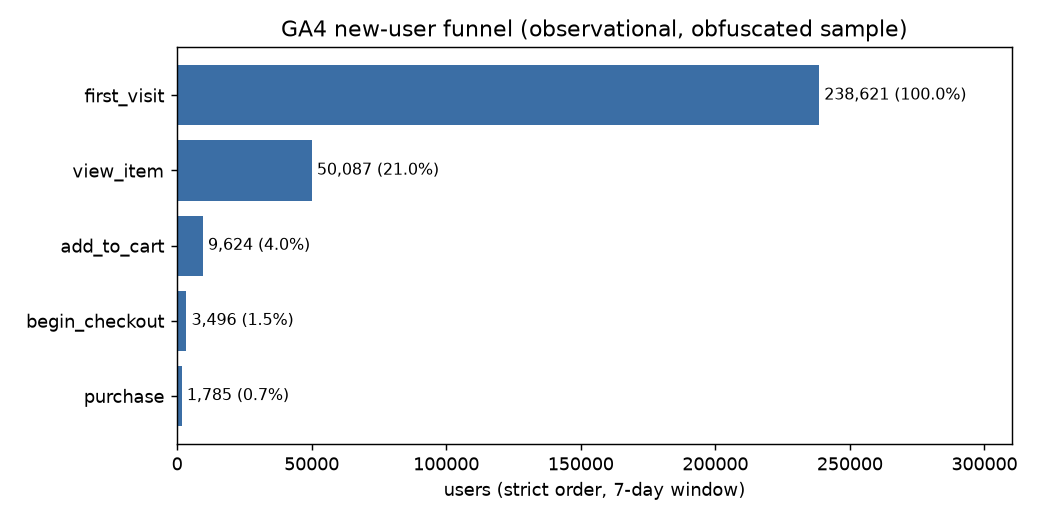

In [3]:
display(r['funnel_strict']); display(Image(FIG / 'funnel_strict.png'))

## Funnel, any order
For checkout, any order exceeds strict order: many users reach checkout without an `add_to_cart` event in the window (for example, "buy now" or a cart from before t0).

In [4]:
r['funnel_any_order']

,stage,users,share_of_entrants,conv_from_prev,conv_ci_low,conv_ci_high,users_lost,drop_rate
0,first_visit,238621,1.0000,NaN,NaN,NaN,NaN,NaN
1,view_item,50087,0.2099,0.2099,0.2083,0.2115,188534.0,0.7901
2,add_to_cart,9627,0.0403,0.1922,0.1888,0.1957,40460.0,0.8078
3,begin_checkout,7213,0.0302,0.7492,0.7405,0.7578,2414.0,0.2508
4,purchase,2757,0.0116,0.3822,0.3711,0.3935,4456.0,0.6178


In [5]:
pd.DataFrame(r['median_time_between_stages']).T

,median_minutes,n
sec_visit_to_view,0.7500,50087.0
sec_view_to_cart,0.2833,9624.0
sec_cart_to_checkout,5.1750,3496.0
sec_checkout_to_purchase,3.6667,1785.0


## Segments (≥ 500 users entering the stage)
Each segment is compared with everyone else at the same stage. The CIs are Newcombe intervals, and the Holm correction runs across all segment tests in a dimension.

In [6]:
seg = r['segment_funnel']
seg.sort_values('vs_rest_p')[['segment_type','segment','stage','n_entering','rate','ci_low','ci_high','diff_vs_rest_pp','vs_rest_ci_low_pp','vs_rest_ci_high_pp','vs_rest_p','vs_rest_p_holm']].head(15)

,segment_type,segment,stage,n_entering,rate,ci_low,ci_high,diff_vs_rest_pp,vs_rest_ci_low_pp,vs_rest_ci_high_pp,vs_rest_p,vs_rest_p_holm
5,channel,Direct,add_to_cart,11943,0.2003,0.1932,0.2076,1.0687,0.2572,1.8942,0.0097,0.1743
35,country,Germany,view_item,4316,0.1953,0.1838,0.2074,-1.4851,-2.6523,-0.2643,0.0176,0.4927
43,country,Other,add_to_cart,12733,0.1852,0.1785,0.1920,-0.9329,-1.7115,-0.1413,0.0210,0.5678
13,channel,Paid Search,add_to_cart,2701,0.1759,0.1620,0.1907,-1.7213,-3.1561,-0.1984,0.0272,0.4625
9,channel,Organic Search,add_to_cart,19269,0.1875,0.1820,0.1930,-0.7629,-1.4671,-0.0538,0.0350,0.5598
18,device,desktop,view_item,138609,0.2112,0.2091,0.2134,0.3128,-0.0184,0.6433,0.0641,0.6414
22,device,mobile,view_item,94662,0.2080,0.2055,0.2106,-0.3095,-0.6427,0.0246,0.0694,0.6414
53,country,United States,add_to_cart,22064,0.1955,0.1903,0.2008,0.6035,-0.0913,1.3007,0.0888,1.0000
41,country,Italy,add_to_cart,720,0.1722,0.1464,0.2015,-2.0214,-4.6272,0.9289,0.1717,1.0000
29,country,Canada,add_to_cart,3811,0.1999,0.1876,0.2129,0.8444,-0.4464,2.1921,0.2034,1.0000


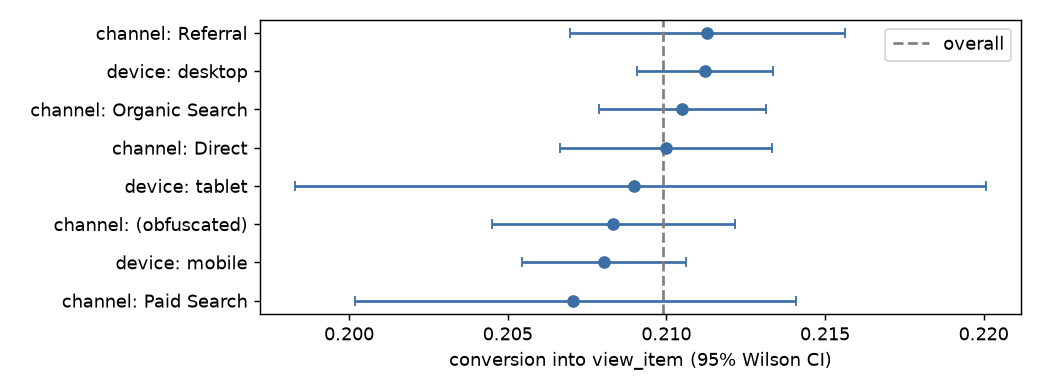

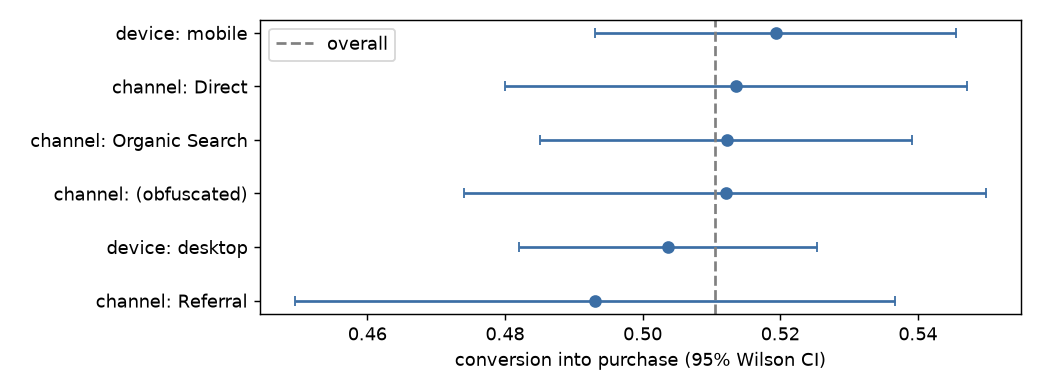

In [7]:
display(Image(FIG / 'segment_view_item_ci.png')); display(Image(FIG / 'segment_purchase_ci.png'))

## Device gap within channel (Simpson's paradox check)

In [8]:
s = r['simpson_device_purchase']
print('raw gap (mobile - desktop, pp):', round(s['raw']['gap_pp'],3), [round(s['raw']['ci_low_pp'],3), round(s['raw']['ci_high_pp'],3)])
print('channel-standardized gap (pp):', round(s['channel_standardized_gap_pp'],3))
s['within_channel']

raw gap (mobile - desktop, pp): 0.026 [-0.045, 0.098]
channel-standardized gap (pp): 0.026


,channel,n_desktop,n_mobile,rate_desktop,rate_mobile,gap_pp_mobile_minus_desktop,ci_low_pp,ci_high_pp,p_value,desktop_share_of_channel,p_holm
0,(obfuscated),24986,17127,0.0078,0.0079,0.0136,-0.1556,0.1903,0.8763,0.5933,1.0000
1,Direct,33070,22548,0.0069,0.0089,0.2020,0.0531,0.3577,0.0075,0.5946,0.0376
2,Organic Search,53149,36348,0.0074,0.0073,-0.0085,-0.1208,0.1073,0.8839,0.5939,1.0000
3,Paid Search,7611,5129,0.0076,0.0062,-0.1382,-0.4248,0.1699,0.3612,0.5974,1.0000
4,Referral,19793,13510,0.0076,0.0067,-0.0967,-0.2771,0.0920,0.3065,0.5943,1.0000


## Opportunity sizing: a scenario, not a forecast

In [9]:
r['opportunity_sizing']

{'label': 'ESTIMATE / SCENARIO - not a forecast',
 'biggest_drop_stage': 'first_visit -> view_item',
 'users_at_stage': 238621,
 'users_lost': 188534,
 'drop_rate': 0.7900981053637358,
 'scenario_drop_reduction_pp': 1.0,
 'extra_users_reaching_stage': 2386.21,
 'observed_downstream_conversion_to_purchase': 0.035637989897578215,
 'extra_purchasers': np.float64(85.03972787350011),
 'aov_usd_mean': 69.24286677151201,
 'aov_usd_median': 48.0,
 'n_transactions': 4451,
 'extra_revenue_usd': np.float64(5888.394547430405),
 'window': 'new users observed 7 days, 2020-11-01..2021-01-24 first visits (~12 weeks)',
 'assumptions': ['downstream conversion of marginal users equals that of current users',
  'AOV unchanged',
  'no cannibalisation; obfuscated sample revenue']}

## Return rates (window-based, censored users excluded) and sensitivity check

In [10]:
for k, v in r['return_rates'].items():
    print(k); display(v)

d7_window


,segment,n,x,rate,ci_low,ci_high
0,all,238621,18741,0.0785,0.0775,0.0796


d7_exact_day


,segment,n,x,rate,ci_low,ci_high
0,all,238621,1601,0.0067,0.0064,0.007


d30_window


...

,segment,n,x,rate,ci_low,ci_high
0,desktop,138609,10862,0.0784,0.0770,0.0798
1,mobile,94662,7450,0.0787,0.0770,0.0804
2,tablet,5350,429,0.0802,0.0732,0.0878


d30_by_channel


,segment,n,x,rate,ci_low,ci_high
0,(obfuscated),30746,3134,0.1019,0.0986,0.1054
1,Direct,40520,4369,0.1078,0.1048,0.1109
2,Organic Search,65387,6958,0.1064,0.1041,0.1088
3,Paid Search,9395,1028,0.1094,0.1033,0.1159
4,Referral,24338,2521,0.1036,0.0998,0.1075


d30_by_device


,segment,n,x,rate,ci_low,ci_high
0,desktop,99107,10421,0.1051,0.1033,0.1071
1,mobile,67460,7178,0.1064,0.1041,0.1088
2,tablet,3819,411,0.1076,0.0982,0.1178


In [11]:
r['segment_return_tests']

,segment_type,metric,n_segments,chi2,p_value,dof,p_holm,p_holm_all
0,channel,return_d7,5,5.2260,0.2649,4,0.5298,0.7947
1,device,return_d7,3,0.2935,0.8635,2,0.8635,1.0000
2,channel,return_d30,5,9.4311,0.0512,4,0.1024,0.2047
3,device,return_d30,3,0.8207,0.6634,2,0.6634,1.0000


## Weekly cohort retention
A cell is shown only if every user in the cohort was observed through the end of week k. Cohorts below 100 users are greyed out. The sample covers about three months, so 30-day return exists only for first visits on or before 2021-01-01.

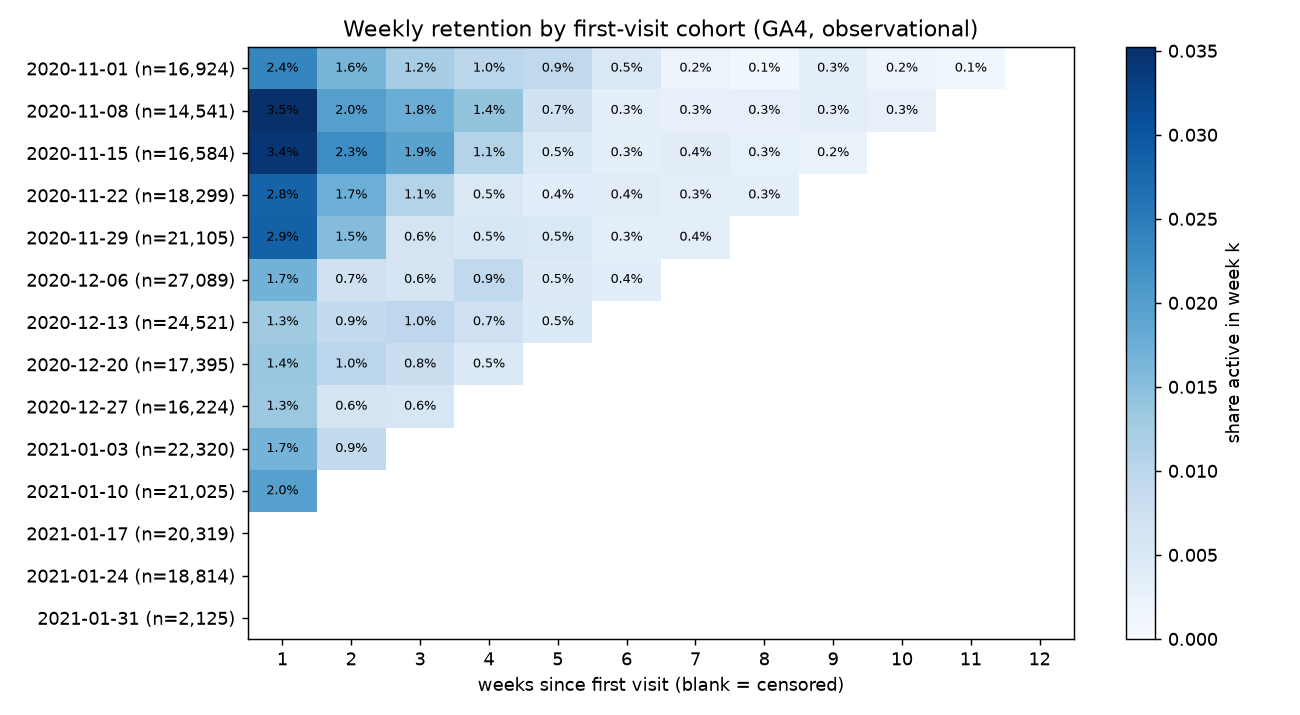

,age_week,n_cohorts,min_rate,max_rate,chi2,p_value,dof,p_holm
0,1,11,0.0130,0.0352,595.7092,1.4624e-121,10,5.8494e-121
1,2,10,0.0062,0.0227,440.0502,3.8394e-89,9,1.1518e-88
2,3,9,0.0057,0.0193,347.5649,2.9966e-70,8,5.9933e-70
3,4,8,0.0049,0.0140,149.9766,4.1060e-29,7,4.1060e-29


In [12]:
display(Image(FIG / 'cohort_heatmap.png'))
r['cohort_equal_age_tests']

**Reading.** Cohorts differ significantly at every age (chi-square, Holm). Early-November cohorts retained best. December cohorts, with their holiday traffic, retained worst in week 1. Channel and device show no detectable difference in D7 or D30 return after Holm. These are descriptive patterns in an obfuscated sample, not causal effects.